# Philly terrain graph under different sampling schemes (2026-10-13)

This notebook shows how the node-sampling scheme and the graph construction change the Philadelphia terrain graph.
The code lives in `spnn/graphs/point_sampling.py` (node samples) and `spnn/graphs/point_graph.py` (graphs on point sets).

- **Regular grid (stride r)**: every r-th DEM row and column, 8-neighbour edges (`construct_nx_graph`). This is the `make_dataset --resolution r` scheme.
- **Uniform**: N DEM cells drawn uniformly at random without replacement.
- **Poisson-disk**: blue-noise sample (Bridson), no two nodes closer than d. d is calibrated so N matches the grid.
- **Slope-adaptive**: N cells drawn without replacement with density 0.5 uniform + 0.5 proportional to |grad z|.
- **Quadtree**: the existing `quadtree.py` simplification. Leaves are blocks with elevation range <= thresh; nodes are leaf corners. thresh is bisected so N roughly matches the grid.

All irregular samples use N = the node count of the grid at the same stride r. Irregular point sets use Delaunay edges by default.
Edge weights are the unscaled 3D Euclidean length (km).

In [1]:
import sys, io, contextlib, time
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

from spnn.graphs.grid import load_dem_data_, get_dem_xv_yv_, construct_nx_graph, DATASET_INFO
from spnn.graphs import point_sampling as ps
from spnn.graphs import point_graph as pg

@contextlib.contextmanager
def quiet():
    # construct_nx_graph and quadtree print progress bars; hide them.
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield

SEED = 0
STRIDES = [40, 20, 10]          # coarse -> fine
MID = 20
SCHEMES = ['grid', 'uniform', 'poisson-disk', 'slope-adaptive', 'quadtree']
COLORS = dict(zip(SCHEMES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']))
RES_COLORS = dict(zip(STRIDES, ['#86b6ef', '#2a78d6', '#104281']))
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. The Philly DEM
Full-resolution DEM: 1000 x 1000 cells of 3 m, so a 3 km x 3 km square. Elevations are in km.

Elevation given in imperial units: True
loaded DEM array with shape: (1000, 1000)
shape (1000, 1000), extent 3.00 x 3.00 km, elevation 18.1-135.2 m


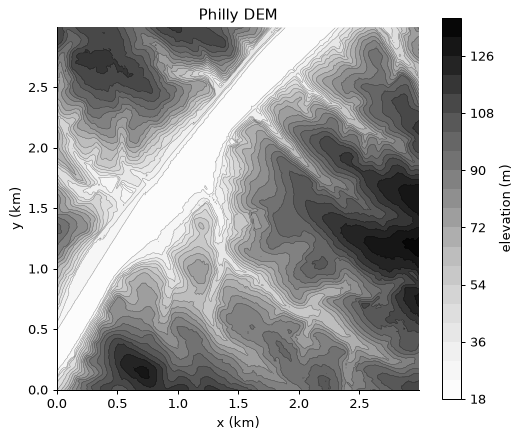

In [2]:
cell_m, imperial = DATASET_INFO['phil']
dem = load_dem_data_(str(Path.home() / 'data/spnn/flat-phil-data-1.txt'), imperial=imperial)
xv, yv, z = get_dem_xv_yv_(dem, cell_m, visualize=False)
rows, cols = z.shape
print(f"shape {z.shape}, extent {xv.max():.2f} x {yv.max():.2f} km, elevation {z.min()*1000:.1f}-{z.max()*1000:.1f} m")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cf = ax.contourf(xv[::2, ::2], yv[::2, ::2], z[::2, ::2] * 1000, levels=20, cmap='Greys')
ax.contour(xv[::4, ::4], yv[::4, ::4], z[::4, ::4] * 1000, levels=20, colors='k', linewidths=0.3, alpha=0.5)
fig.colorbar(cf, ax=ax, label='elevation (m)')
ax.set(xlabel='x (km)', ylabel='y (km)', title='Philly DEM'); ax.set_aspect('equal')
plt.show()

## 2. Node sets and graphs per scheme and resolution
Rows are schemes, columns are resolution levels named by the equivalent grid stride r.
Each panel draws the edges (thin lines) and nodes (dots) over the elevation contours, with the same axes limits everywhere.
The first cell builds all graphs. Its printout gives N per panel and the calibrated Poisson-disk d and quadtree thresh.

In [3]:
def quadtree_for_count(n_target, lo=1e-3, hi=0.2, iters=14):
    # Node count decreases with thresh; bisect log(thresh).
    best = None
    for _ in range(iters):
        mid = np.sqrt(lo * hi)
        with quiet():
            G, f, idx = pg.build_quadtree_graph(xv, yv, z, mid)
        n = G.number_of_nodes()
        if best is None or abs(n - n_target) < abs(best[3] - n_target):
            best = (G, f, mid, n)
        if n > n_target: lo = mid
        else: hi = mid
    return best[0], best[1], best[2]

graphs, info = {}, {}
t0 = time.time()
for r in STRIDES:
    with quiet():
        G, f = construct_nx_graph(xv[::r, ::r], yv[::r, ::r], z[::r, ::r], p=2, scale=False)
    graphs['grid', r] = (G, np.array(f)); n = G.number_of_nodes()
    info['grid', r] = f'stride {r}'

    f, _ = ps.sample_uniform(xv, yv, z, n, seed=SEED)
    graphs['uniform', r] = pg.build_delaunay_graph(f)

    f, _, d = ps.sample_poisson_disk(xv, yv, z, n_target=n, seed=SEED)
    graphs['poisson-disk', r] = pg.build_delaunay_graph(f)
    info['poisson-disk', r] = f'd = {d*1000:.1f} m (grid spacing {r*cell_m} m)'

    f, _ = ps.sample_slope_adaptive(xv, yv, z, n, uniform_mix=0.5, seed=SEED)
    graphs['slope-adaptive', r] = pg.build_delaunay_graph(f)

    G, f, th = quadtree_for_count(n)
    graphs['quadtree', r] = (G, f)
    info['quadtree', r] = f'thresh = {th*1000:.2f} m'
print(f'built {len(graphs)} graphs in {time.time()-t0:.0f} s')
for (s, r), (G, f) in graphs.items():
    print(f'{s:15s} r={r:3d}  N={G.number_of_nodes():6d}  E={G.number_of_edges():6d}  {info.get((s, r), "")}')

built 15 graphs in 21 s
grid            r= 40  N=   625  E=  2352  stride 40
uniform         r= 40  N=   625  E=  1856  
poisson-disk    r= 40  N=   629  E=  1867  d = 95.8 m (grid spacing 120 m)
slope-adaptive  r= 40  N=   625  E=  1852  
quadtree        r= 40  N=   625  E=  1099  thresh = 39.29 m
grid            r= 20  N=  2500  E=  9702  stride 20
uniform         r= 20  N=  2500  E=  7473  
poisson-disk    r= 20  N=  2497  E=  7470  d = 47.8 m (grid spacing 60 m)
slope-adaptive  r= 20  N=  2500  E=  7471  
quadtree        r= 20  N=  2494  E=  4453  thresh = 22.54 m
grid            r= 10  N= 10000  E= 39402  stride 10
uniform         r= 10  N= 10000  E= 29940  
poisson-disk    r= 10  N= 10032  E= 30032  d = 23.8 m (grid spacing 30 m)
slope-adaptive  r= 10  N= 10000  E= 29934  
quadtree        r= 10  N=  9998  E= 18119  thresh = 11.74 m


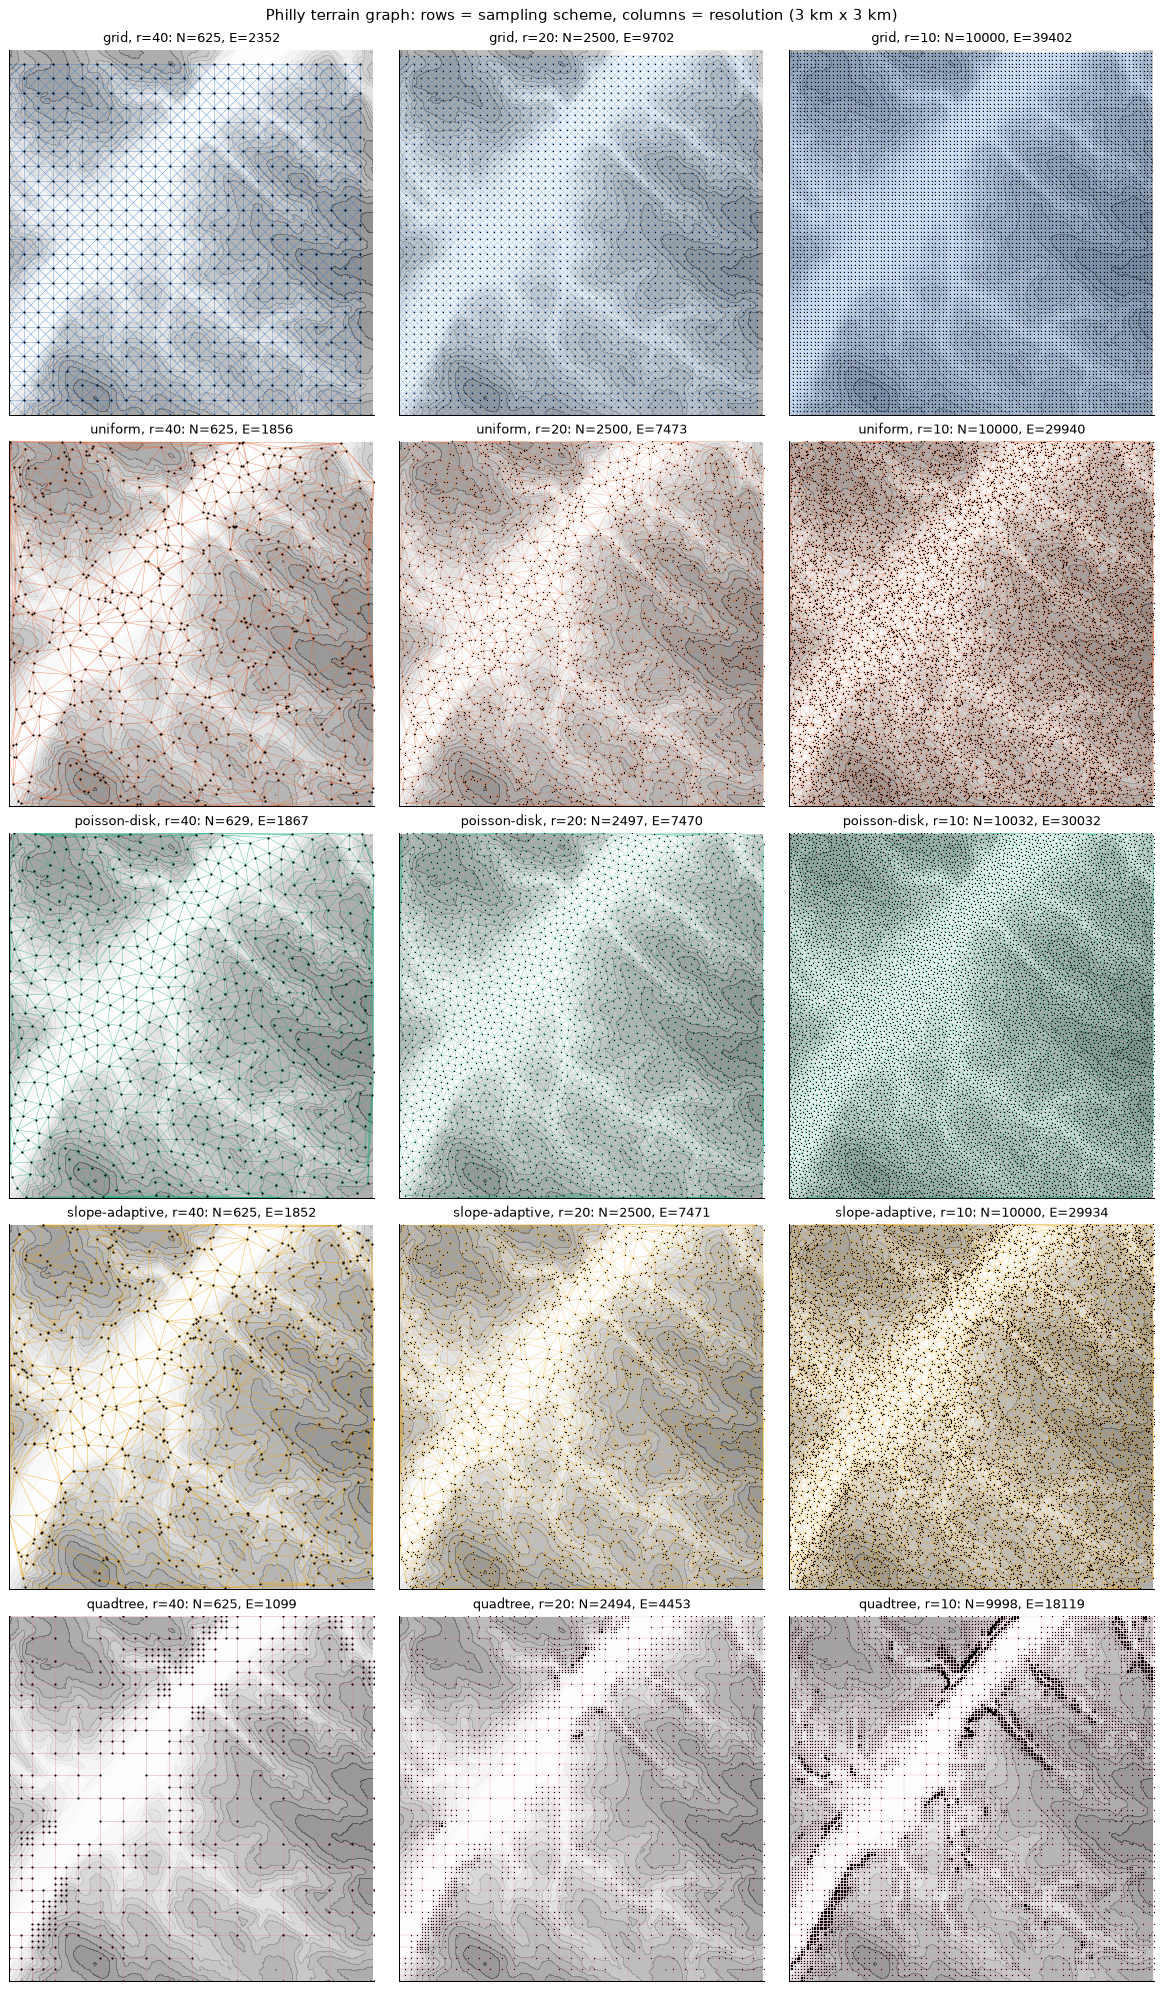

In [4]:
zx, zy, zz = xv[::5, ::5], yv[::5, ::5], z[::5, ::5] * 1000

def draw(ax, G, f, color, lw=0.3, ms=1.5, contours=True):
    if contours:
        ax.contourf(zx, zy, zz, levels=15, cmap='Greys', alpha=0.45)
    f = np.asarray(f)
    e = np.array(G.edges())
    if len(e):
        ax.add_collection(LineCollection(f[e][:, :, :2], colors=color, linewidths=lw, alpha=0.7))
    ax.scatter(f[:, 0], f[:, 1], s=ms, c='k', linewidths=0, zorder=3)
    ax.set_xlim(0, xv.max()); ax.set_ylim(0, yv.max()); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(len(SCHEMES), len(STRIDES), figsize=(13, 22), constrained_layout=True)
for i, s in enumerate(SCHEMES):
    for j, r in enumerate(STRIDES):
        G, f = graphs[s, r]
        draw(axes[i, j], G, f, COLORS[s], lw=0.4 if r == 40 else 0.25, ms=3 if r == 40 else 1)
        axes[i, j].set_title(f'{s}, r={r}: N={G.number_of_nodes()}, E={G.number_of_edges()}', fontsize=10)
fig.suptitle('Philly terrain graph: rows = sampling scheme, columns = resolution (3 km x 3 km)')
plt.show()

The fine panels are too dense to read at full extent. The next figure zooms into a 0.6 km x 0.6 km window at r = 20, where the local structure of each scheme is visible.

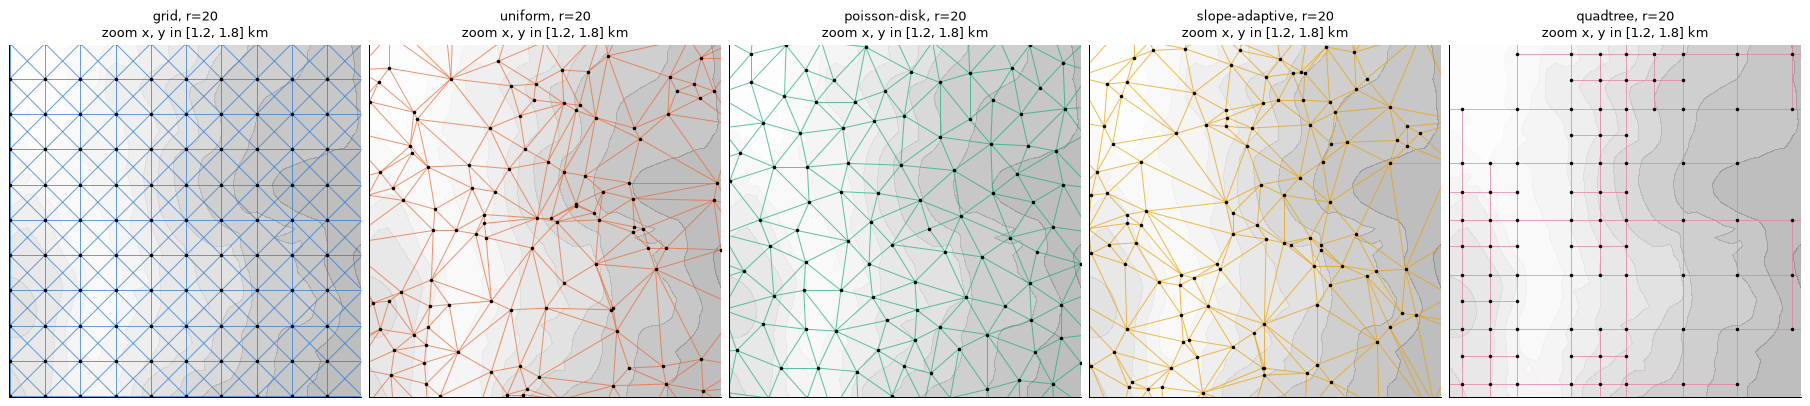

In [5]:
win = (1.2, 1.8, 1.2, 1.8)
fig, axes = plt.subplots(1, len(SCHEMES), figsize=(20, 4.8), constrained_layout=True)
for ax, s in zip(axes, SCHEMES):
    G, f = graphs[s, MID]
    draw(ax, G, f, COLORS[s], lw=0.8, ms=8)
    ax.set_xlim(win[0], win[1]); ax.set_ylim(win[2], win[3]); ax.set_title(f'{s}, r={MID}\nzoom x, y in [{win[0]}, {win[1]}] km', fontsize=10)
plt.show()

## 3. Graph constructions on one Poisson-disk point set (r = 20)
The same node set, three edge rules: symmetrized kNN with k = 8 (the grid's degree), Delaunay, and the radius (epsilon-ball) graph with radius 1.5 x the mean nearest-neighbour spacing.
The radius graph is the closest to the kernel graph in the paper's theory. The second table repeats the comparison for every irregular point set at r = 20.

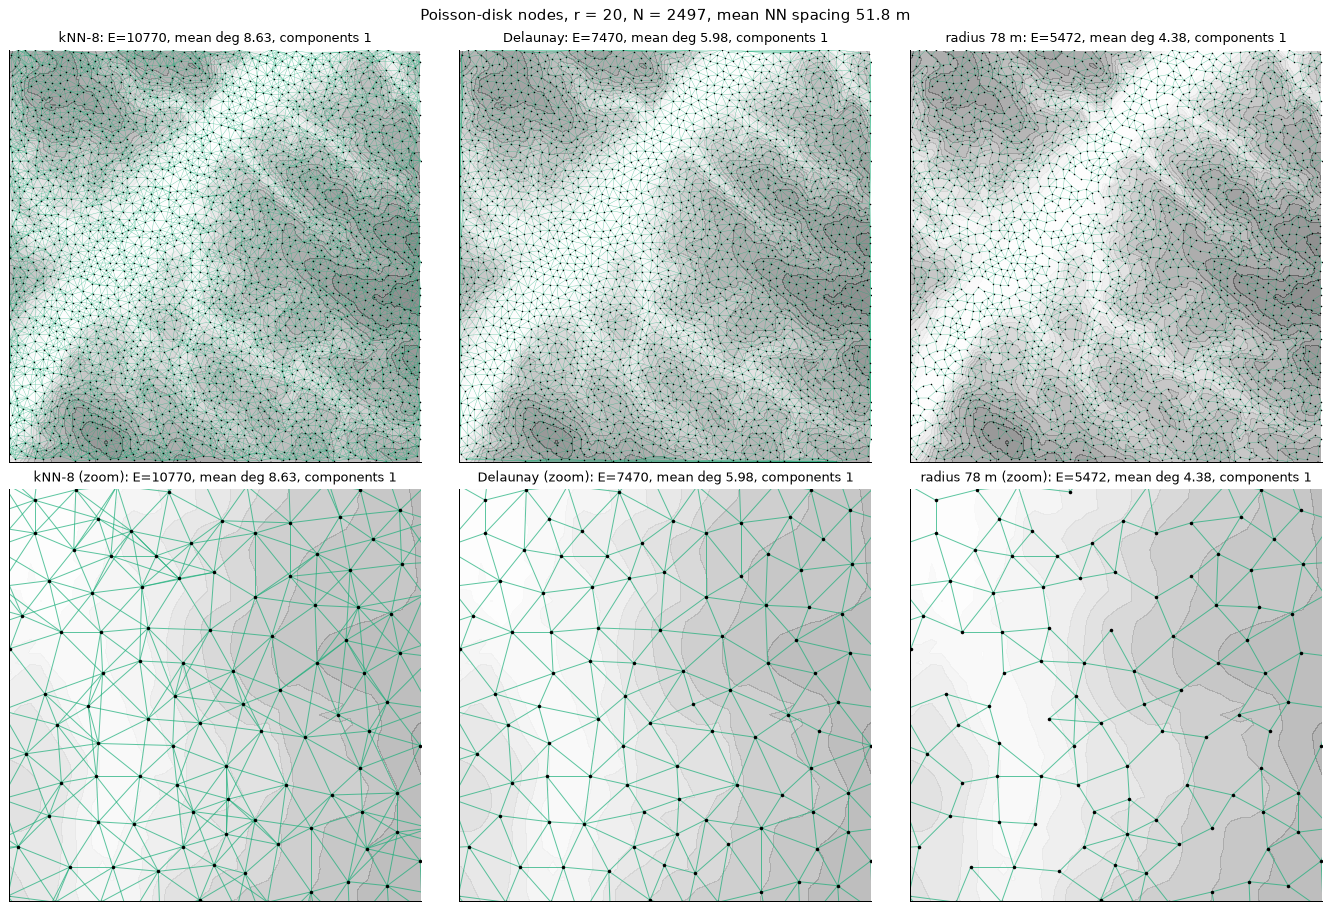

,scheme,construction,N,E,mean_degree,components,largest_component_frac
0,uniform,kNN-8,2500,11521,9.217,1,1.000
1,uniform,Delaunay,2500,7473,5.978,1,1.000
2,uniform,radius 1.5h,2500,2222,1.778,909,0.012
3,poisson-disk,kNN-8,2497,10770,8.626,1,1.000
4,poisson-disk,Delaunay,2497,7470,5.983,1,1.000
5,poisson-disk,radius 1.5h,2497,5472,4.383,1,1.000
6,slope-adaptive,kNN-8,2500,11704,9.363,1,1.000
7,slope-adaptive,Delaunay,2500,7471,5.977,1,1.000
8,slope-adaptive,radius 1.5h,2500,2299,1.839,940,0.011


In [6]:
f_pd = graphs['poisson-disk', MID][1]
h = pg.mean_nn_spacing(f_pd)
cons = {'kNN-8': pg.build_knn_graph(f_pd, k=8)[0],
        'Delaunay': pg.build_delaunay_graph(f_pd)[0],
        f'radius {1.5*h*1000:.0f} m': pg.build_radius_graph(f_pd)[0]}
fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
for j, (name, G) in enumerate(cons.items()):
    cc = nx.number_connected_components(G)
    deg = np.mean([d for _, d in G.degree()])
    for i, zoom in enumerate([False, True]):
        ax = axes[i, j]
        draw(ax, G, f_pd, COLORS['poisson-disk'], lw=0.3 if not zoom else 0.8, ms=1.5 if not zoom else 8)
        if zoom:
            ax.set_xlim(win[0], win[1]); ax.set_ylim(win[2], win[3])
        ax.set_title(f'{name}{" (zoom)" if zoom else ""}: E={G.number_of_edges()}, mean deg {deg:.2f}, components {cc}', fontsize=10)
fig.suptitle(f'Poisson-disk nodes, r = {MID}, N = {len(f_pd)}, mean NN spacing {h*1000:.1f} m')
plt.show()

rows_c = []
for s in ['uniform', 'poisson-disk', 'slope-adaptive']:
    f = graphs[s, MID][1]
    for name, fn in [('kNN-8', lambda f: pg.build_knn_graph(f, k=8)), ('Delaunay', pg.build_delaunay_graph), ('radius 1.5h', pg.build_radius_graph)]:
        G = fn(f)[0]
        comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
        rows_c.append(dict(scheme=s, construction=name, N=G.number_of_nodes(), E=G.number_of_edges(),
                           mean_degree=2 * G.number_of_edges() / G.number_of_nodes(),
                           components=len(comps), largest_component_frac=comps[0] / G.number_of_nodes()))
pd.DataFrame(rows_c).round(3)

Disconnected graphs are reported as they are, not repaired. A graph with more than one component has pairs with no finite shortest path.

## 4. Summary table (default construction per scheme)
Lengths are 3D edge weights in km; `max_edge_km` is the longest xy edge.
Delaunay on all three random point sets (uniform, Poisson-disk, slope-adaptive) has long thin triangles along the domain boundary (the convex hull).
These give the km-long maximum edges. `edges_gt_3x_median` counts edges longer than 3 x the median.

In [7]:
rows_s = []
for (s, r), (G, f) in graphs.items():
    f = np.asarray(f)
    w = np.array([d['weight'] for *_, d in G.edges(data=True)])
    e = np.array(G.edges())
    lxy = np.linalg.norm(f[e[:, 0], :2] - f[e[:, 1], :2], axis=1)
    rows_s.append(dict(scheme=s, r=r, N=G.number_of_nodes(), E=G.number_of_edges(),
                       mean_degree=2 * G.number_of_edges() / G.number_of_nodes(),
                       mean_edge_km=w.mean(), median_edge_km=np.median(w), max_edge_km=lxy.max(),
                       edges_gt_3x_median=int((w > 3 * np.median(w)).sum()),
                       components=nx.number_connected_components(G)))
summary = pd.DataFrame(rows_s).sort_values(['r', 'scheme'], ascending=[False, True]).reset_index(drop=True)
summary.round(4)

,scheme,r,N,E,mean_degree,mean_edge_km,median_edge_km,max_edge_km,edges_gt_3x_median,components
0,grid,40,625,2352,7.5264,0.1452,0.1242,0.1699,0,1
1,poisson-disk,40,629,1867,5.9364,0.1528,0.1350,2.0691,36,1
2,quadtree,40,625,1099,3.5168,0.1092,0.0940,0.3754,19,1
3,slope-adaptive,40,625,1852,5.9264,0.1478,0.1322,1.4655,34,1
4,uniform,40,625,1856,5.9392,0.1527,0.1355,2.5706,40,1
5,grid,20,2500,9702,7.7616,0.0729,0.0641,0.0849,0,1
6,poisson-disk,20,2497,7470,5.9832,0.0738,0.0664,2.2643,83,1
7,quadtree,20,2494,4453,3.5710,0.0526,0.0481,0.1892,70,1
8,slope-adaptive,20,2500,7471,5.9768,0.0723,0.0642,1.4204,114,1
9,uniform,20,2500,7473,5.9784,0.0729,0.0662,2.4204,83,1


## 5. Physical radius covered by k hops
This is relevant to the sparse GT k-hop window. For each graph I pick 50 random source nodes.
For each source and k, the radius is the largest xy distance (km) from the source to any node within k hops; the plot shows the mean over sources.
Sources within 0.3 km of the domain edge are excluded so the boundary does not cap the radius at small k.

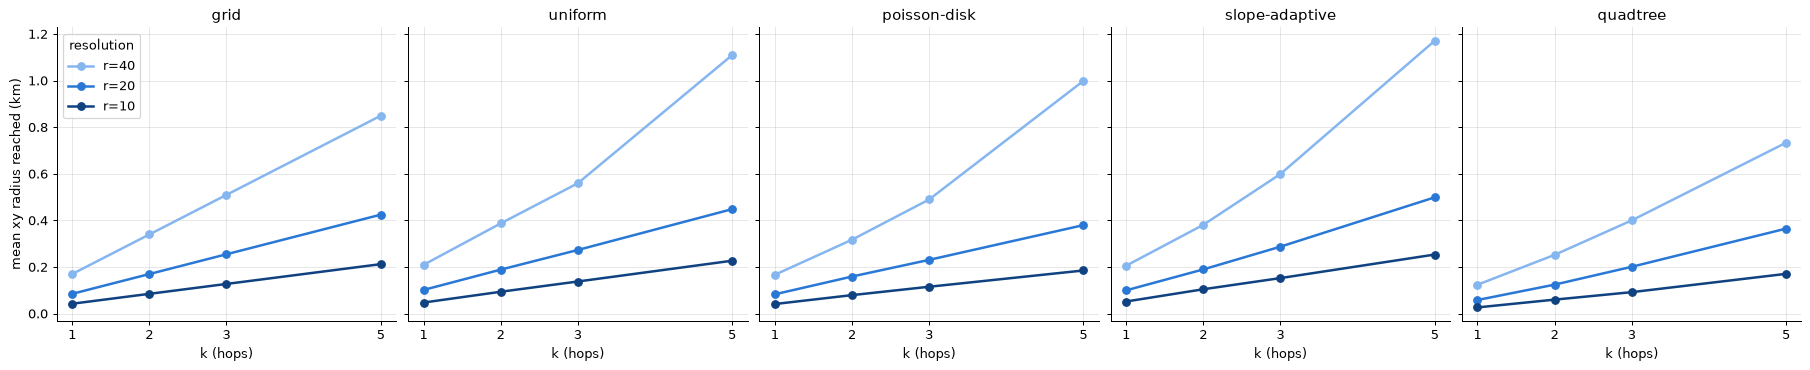

k                      1      2      3      5
scheme         r                             
grid           10  0.042  0.085  0.127  0.212
               20  0.085  0.170  0.255  0.425
               40  0.170  0.340  0.510  0.849
poisson-disk   10  0.041  0.079  0.115  0.185
               20  0.083  0.159  0.231  0.380
               40  0.167  0.317  0.490  0.999
quadtree       10  0.027  0.060  0.092  0.171
               20  0.058  0.124  0.201  0.365
               40  0.124  0.252  0.400  0.733
slope-adaptive 10  0.052  0.105  0.153  0.254
               20  0.100  0.190  0.287  0.499
               40  0.206  0.381  0.599  1.171
uniform        10  0.047  0.094  0.138  0.227
               20  0.102  0.189  0.273  0.448
               40  0.209  0.387  0.559  1.109

In [8]:
KS = [1, 2, 3, 5]
rng = np.random.default_rng(SEED)
rows_k = []
for (s, r), (G, f) in graphs.items():
    f = np.asarray(f)
    inner = np.where((f[:, 0] > 0.3) & (f[:, 0] < xv.max() - 0.3) & (f[:, 1] > 0.3) & (f[:, 1] < yv.max() - 0.3))[0]
    srcs = rng.choice(inner, size=min(50, len(inner)), replace=False)
    rad = np.zeros((len(srcs), len(KS)))
    for a, u in enumerate(srcs):
        hops = nx.single_source_shortest_path_length(G, int(u), cutoff=max(KS))
        nodes = np.fromiter(hops.keys(), int); hk = np.fromiter(hops.values(), int)
        dist = np.linalg.norm(f[nodes, :2] - f[u, :2], axis=1)
        for b, k in enumerate(KS):
            rad[a, b] = dist[hk <= k].max()
    for b, k in enumerate(KS):
        rows_k.append(dict(scheme=s, r=r, k=k, radius_km=rad[:, b].mean()))
khop = pd.DataFrame(rows_k)

fig, axes = plt.subplots(1, len(SCHEMES), figsize=(20, 4), sharey=True, constrained_layout=True)
for ax, s in zip(axes, SCHEMES):
    for r in STRIDES:
        d = khop[(khop.scheme == s) & (khop.r == r)]
        ax.plot(d.k, d.radius_km, marker='o', ms=6, lw=2, color=RES_COLORS[r], label=f'r={r}')
    ax.set(title=s, xlabel='k (hops)', xticks=KS); ax.grid(alpha=0.3)
axes[0].set_ylabel('mean xy radius reached (km)'); axes[0].legend(title='resolution')
plt.show()
khop.pivot_table(index=['scheme', 'r'], columns='k', values='radius_km').round(3)

Dividing the radius by k gives the physical distance per hop. The k needed to cover a fixed radius scales roughly with 1/(spacing), so halving r doubles the hops needed.

In [9]:
per_hop = khop.assign(km_per_hop=khop.radius_km / khop.k).pivot_table(index=['scheme', 'r'], columns='k', values='km_per_hop')
per_hop.round(4)

k                       1       2       3       5
scheme         r                                 
grid           10  0.0425  0.0425  0.0425  0.0425
               20  0.0849  0.0849  0.0849  0.0849
               40  0.1699  0.1699  0.1699  0.1699
poisson-disk   10  0.0412  0.0397  0.0384  0.0370
               20  0.0829  0.0796  0.0769  0.0759
               40  0.1667  0.1586  0.1633  0.1998
quadtree       10  0.0267  0.0300  0.0307  0.0341
               20  0.0584  0.0622  0.0670  0.0730
               40  0.1240  0.1261  0.1334  0.1467
slope-adaptive 10  0.0520  0.0523  0.0508  0.0507
               20  0.0999  0.0949  0.0958  0.0998
               40  0.2056  0.1905  0.1997  0.2342
uniform        10  0.0475  0.0469  0.0460  0.0454
               20  0.1016  0.0944  0.0910  0.0897
               40  0.2093  0.1935  0.1865  0.2218

## 6. Degree and edge-length histograms (r = 20)
Edge lengths are capped at 4 x the grid spacing; longer edges (Delaunay hull edges) go in the last bin.

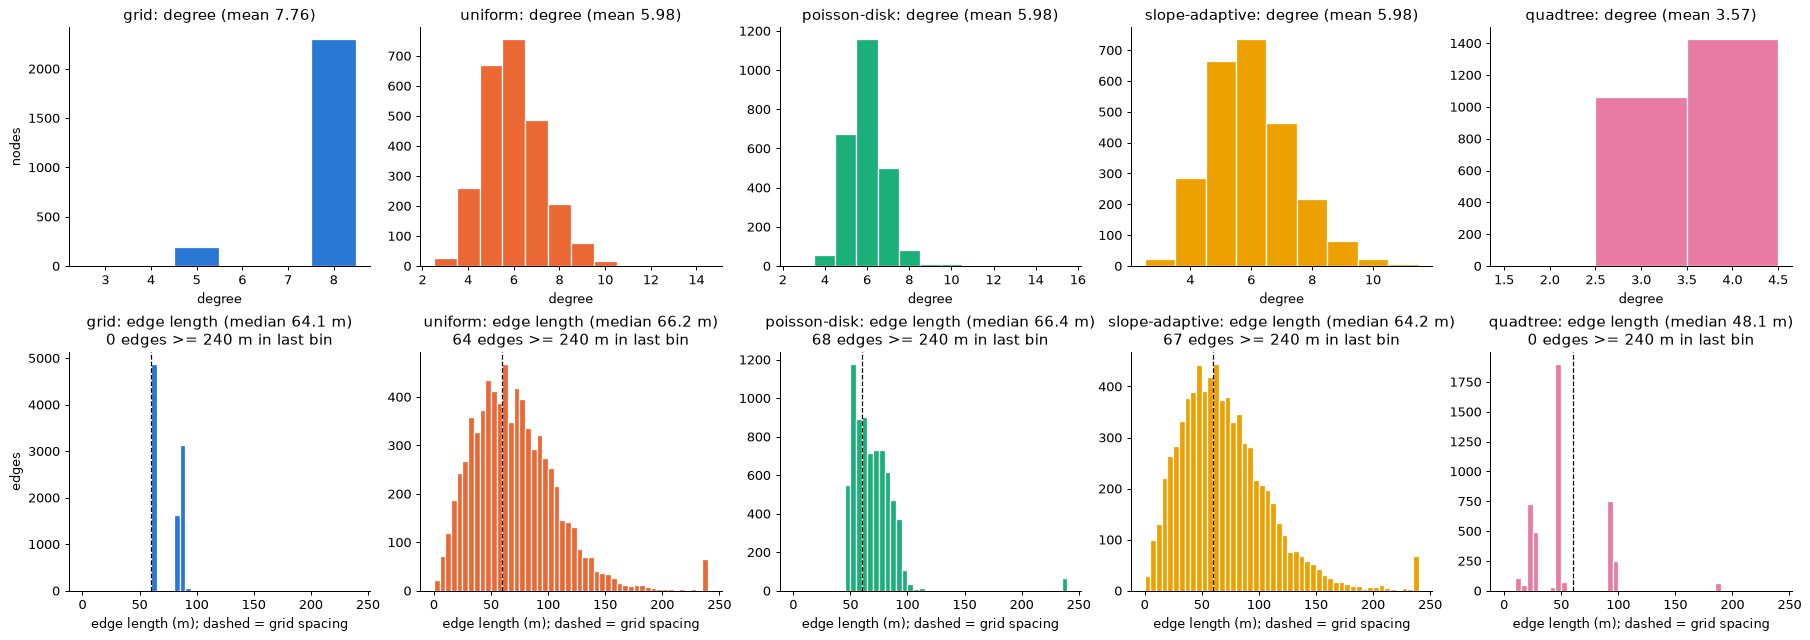

In [10]:
fig, axes = plt.subplots(2, len(SCHEMES), figsize=(20, 7), constrained_layout=True)
for j, s in enumerate(SCHEMES):
    G, f = graphs[s, MID]
    deg = np.array([d for _, d in G.degree()])
    w = np.array([d['weight'] for *_, d in G.edges(data=True)]) * 1000
    axes[0, j].hist(deg, bins=np.arange(deg.min(), deg.max() + 2) - 0.5, color=COLORS[s], edgecolor='white')
    axes[0, j].set(title=f'{s}: degree (mean {deg.mean():.2f})', xlabel='degree')
    wmax = 4 * MID * cell_m
    axes[1, j].hist(np.minimum(w, wmax), bins=np.linspace(0, wmax, 49), color=COLORS[s], edgecolor='white')
    axes[1, j].axvline(MID * cell_m, color='k', ls='--', lw=1)
    axes[1, j].set(title=f'{s}: edge length (median {np.median(w):.1f} m)\n{(w >= wmax).sum()} edges >= {wmax} m in last bin', xlabel='edge length (m); dashed = grid spacing')
axes[0, 0].set_ylabel('nodes'); axes[1, 0].set_ylabel('edges')
plt.show()